In [1]:
%pip install -q --upgrade kaggle==2.2.5
!apt-get update -qq
!apt-get install -y -qq unrar
%pip install -q --upgrade kagglehub

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [2]:
import os
from google.colab import userdata

os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")

print("Kaggle credentials loaded.")

Kaggle credentials loaded.


In [3]:
import os
from google.colab import userdata

os.environ["KAGGLE_USERNAME"] = userdata.get(
    "KAGGLE_USERNAME"
)

os.environ["KAGGLE_KEY"] = userdata.get(
    "KAGGLE_KEY"
)

assert os.environ["KAGGLE_USERNAME"], (
    "KAGGLE_USERNAME is missing from Colab Secrets."
)

assert os.environ["KAGGLE_KEY"], (
    "KAGGLE_KEY is missing from Colab Secrets."
)

print("Kaggle credentials loaded securely.")

Kaggle credentials loaded securely.


In [4]:
import os
import random
import numpy as np
import torch

SEED = 42

def set_seed(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    # Deterministic cuDNN behaviour
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    # Ask PyTorch to use deterministic algorithms when possible
    torch.use_deterministic_algorithms(
        True,
        warn_only=True
    )
set_seed(SEED)

print("Random seed fixed:", SEED)

Random seed fixed: 42


In [5]:
!kaggle datasets download \
    -d colvertgomez/goes16-wildfires-smoke-plumes-dataset \
    -p /content/downloads

Dataset URL: https://www.kaggle.com/datasets/colvertgomez/goes16-wildfires-smoke-plumes-dataset
License(s): MIT
goes16-wildfires-smoke-plumes-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)


In [6]:
from pathlib import Path
import zipfile

ZIP_PATH = Path(
    "/content/downloads/goes16-wildfires-smoke-plumes-dataset.zip"
)

EXTRACT_DIR = Path("/content/goes16_dataset")
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

TARGET_FOLDER = "GOES16-wildfires-smoke-plumes-dataset-2da/"

with zipfile.ZipFile(ZIP_PATH, "r") as archive:

    matching_files = [
        name for name in archive.namelist()
        if name.startswith(TARGET_FOLDER)
    ]

    print("Files to extract:", len(matching_files))

    if not matching_files:
        raise FileNotFoundError(
            f"{TARGET_FOLDER} was not found inside the ZIP."
        )

    for name in matching_files:
        archive.extract(name, EXTRACT_DIR)

print("2da extraction completed.")

Files to extract: 5046
2da extraction completed.


In [7]:
DATASET_ROOT = Path(
    "/content/goes16_dataset/"
    "GOES16-wildfires-smoke-plumes-dataset-2da"
)

In [8]:
import glob
print("Current directory files:")
display(os.listdir('.'))
print("\n--- Detailed Archive Directory Tree ---")
for root, dirs, files in os.walk('.'):
    level = root.replace('.', '').count(os.sep)
    indent = ' ' * 4 * (level)
    print(f"{indent}{os.path.basename(root)}/")
    subindent = ' ' * 4 * (level + 1)
    for f in files[:5]: # display up to first 5 files in each directory
        print(f"{subindent}{f}")

Current directory files:


['.config',
 'downloads',
 'goes16_dataset',
 'checkpoints',
 'data_sanity_results',
 'sample_data']


--- Detailed Archive Directory Tree ---
./
    .config/
        .last_update_check.json
        hidden_gcloud_config_universe_descriptor_data_cache_configs.db
        config_sentinel
        .last_opt_in_prompt.yaml
        default_configs.db
        configurations/
            config_default
        logs/
            2026.10.21/
                13.27.58.650478.log
                13.28.04.564766.log
                13.27.51.774504.log
                13.27.57.480371.log
                13.28.05.116687.log
    downloads/
        goes16-wildfires-smoke-plumes-dataset.zip
    goes16_dataset/
        GOES16-wildfires-smoke-plumes-dataset-2da/
            train_masks/
                CMIPC-M6_G16_s20221202031_tc_r-5524_mask.gif
                CMIPC-M6_G16_s20221101621_tc_r-5276_mask.gif
                CMIPC-M6_G16_s20220952036_tc_r-3194_mask_1.gif
                CMIPC-M6_G16_s20221201846_tc_r-5524_mask_1.gif
                CMIPC-M6_G16_s20221251546_tc_r-5443_mask_1.gif
            val

In [9]:
from pathlib import Path

DATASET_ROOT = Path(
    "/content/goes16_dataset/"
    "GOES16-wildfires-smoke-plumes-dataset-2da"
)

TRAIN_IMAGES = DATASET_ROOT / "train"
TRAIN_MASKS = DATASET_ROOT / "train_masks"

VALID_IMAGES = DATASET_ROOT / "valid"
VALID_MASKS = DATASET_ROOT / "valid_masks"

TEST_IMAGES = DATASET_ROOT / "test"
TEST_MASKS = DATASET_ROOT / "test_masks"

folders = {
    "train": TRAIN_IMAGES,
    "train_masks": TRAIN_MASKS,
    "valid": VALID_IMAGES,
    "valid_masks": VALID_MASKS,
    "test": TEST_IMAGES,
    "test_masks": TEST_MASKS,
}

for name, folder in folders.items():
    files = (
        [path for path in folder.iterdir() if path.is_file()]
        if folder.exists()
        else []
    )

    print(
        f"{name:12} | "
        f"exists={folder.exists()} | "
        f"files={len(files)}"
    )

train        | exists=True | files=2193
train_masks  | exists=True | files=2193
valid        | exists=True | files=207
valid_masks  | exists=True | files=207
test         | exists=True | files=123
test_masks   | exists=True | files=123


In [10]:
from pathlib import Path
from PIL import Image

import re
import numpy as np
import pandas as pd

In [11]:
SPLITS = {
    "train": {
        "images": Path(TRAIN_IMAGES),
        "masks": Path(TRAIN_MASKS),
    },
    "valid": {
        "images": Path(VALID_IMAGES),
        "masks": Path(VALID_MASKS),
    },
    "test": {
        "images": Path(TEST_IMAGES),
        "masks": Path(TEST_MASKS),
    },
}

In [12]:
def expected_mask_name(image_name):
    """
    Examples:
    X.png   -> X_mask.gif
    X_0.png -> X_mask_0.gif
    X_1.png -> X_mask_1.gif
    """

    stem = Path(image_name).stem

    # Check for an augmentation suffix such as _0 or _1
    match = re.match(r"^(.*)_(\d+)$", stem)

    if match:
        base_name = match.group(1)
        augmentation_id = match.group(2)

        return (
            f"{base_name}_mask_"
            f"{augmentation_id}.gif"
        )

    return f"{stem}_mask.gif"

In [13]:
print(
    expected_mask_name(
        "CMIPC-M6_G16_s20221351716_tc_r-9104.png"
    )
)

print(
    expected_mask_name(
        "CMIPC-M6_G16_s20221351716_tc_r-9104_0.png"
    )
)

CMIPC-M6_G16_s20221351716_tc_r-9104_mask.gif
CMIPC-M6_G16_s20221351716_tc_r-9104_mask_0.gif


In [14]:
def pair_images_with_masks(image_dir, mask_dir):

    image_dir = Path(image_dir)
    mask_dir = Path(mask_dir)

    image_files = sorted([
        path
        for path in image_dir.iterdir()
        if path.is_file()
        and path.suffix.lower() == ".png"
    ])

    mask_files = sorted([
        path
        for path in mask_dir.iterdir()
        if path.is_file()
        and path.suffix.lower() == ".gif"
    ])

    mask_lookup = {
        mask_path.name: mask_path
        for mask_path in mask_files
    }

    pairs = []
    missing_masks = []

    for image_path in image_files:

        mask_name = expected_mask_name(
            image_path.name
        )

        mask_path = mask_lookup.get(mask_name)

        if mask_path is None:
            missing_masks.append({
                "image_filename": image_path.name,
                "expected_mask": mask_name,
            })
        else:
            pairs.append(
                (image_path, mask_path)
            )

    # Find masks that were not paired with an image
    paired_mask_names = {
        mask_path.name
        for _, mask_path in pairs
    }

    extra_masks = [
        mask_path.name
        for mask_path in mask_files
        if mask_path.name not in paired_mask_names
    ]

    return {
        "pairs": pairs,
        "image_count": len(image_files),
        "mask_count": len(mask_files),
        "missing_masks": missing_masks,
        "extra_masks": extra_masks,
    }

In [15]:
pairing_results = {}
pairing_summary_rows = []

for split_name, paths in SPLITS.items():

    result = pair_images_with_masks(
        paths["images"],
        paths["masks"],
    )

    pairing_results[split_name] = result

    pairing_summary_rows.append({
        "split": split_name,
        "images": result["image_count"],
        "masks": result["mask_count"],
        "valid_pairs": len(result["pairs"]),
        "missing_masks": len(
            result["missing_masks"]
        ),
        "extra_masks": len(
            result["extra_masks"]
        ),
    })

pairing_summary_df = pd.DataFrame(
    pairing_summary_rows
)

display(pairing_summary_df)

,split,images,masks,valid_pairs,missing_masks,extra_masks
0,train,2193,2193,2193,0,0
1,valid,207,207,207,0,0
2,test,123,123,123,0,0


In [16]:
for split_name, result in pairing_results.items():

    assert result["image_count"] == result["mask_count"], (
        f"{split_name}: image and mask counts differ."
    )

    assert len(result["missing_masks"]) == 0, (
        f"{split_name}: missing masks found:\n"
        f"{result['missing_masks'][:10]}"
    )

    assert len(result["extra_masks"]) == 0, (
        f"{split_name}: extra masks found:\n"
        f"{result['extra_masks'][:10]}"
    )

    assert len(result["pairs"]) == result["image_count"], (
        f"{split_name}: not all images were paired."
    )

print("All images have an exact matching mask.")

All images have an exact matching mask.


In [17]:
dimension_errors = []
unexpected_mask_values = []

for split_name, result in pairing_results.items():

    for image_path, mask_path in result["pairs"]:

        with Image.open(image_path) as image_file:
            image = np.array(
                image_file.convert("RGB")
            )

        with Image.open(mask_path) as mask_file:
            mask = np.array(mask_file)

        if image.shape[:2] != mask.shape[:2]:
            dimension_errors.append({
                "split": split_name,
                "image": image_path.name,
                "mask": mask_path.name,
                "image_shape": image.shape,
                "mask_shape": mask.shape,
            })

        unique_values = np.unique(mask)

        if not set(unique_values).issubset({0, 1}):
            unexpected_mask_values.append({
                "split": split_name,
                "mask": mask_path.name,
                "values": unique_values.tolist(),
            })

assert not dimension_errors, (
    f"Dimension errors found:\n"
    f"{dimension_errors[:10]}"
)

assert not unexpected_mask_values, (
    f"Unexpected mask values found:\n"
    f"{unexpected_mask_values[:10]}"
)

print("All image-mask dimensions match.")
print("All masks contain only binary values 0 and 1.")

All image-mask dimensions match.
All masks contain only binary values 0 and 1.


In [18]:
mask_statistics_rows = []

for split_name, result in pairing_results.items():

    for image_path, mask_path in result["pairs"]:

        with Image.open(mask_path) as mask_file:
            mask = np.array(mask_file)

        binary_mask = (
            mask > 0
        ).astype(np.uint8)

        total_pixels = binary_mask.size
        smoke_pixels = int(
            binary_mask.sum()
        )

        smoke_share = (
            smoke_pixels / total_pixels
        )

        mask_statistics_rows.append({
            "split": split_name,
            "image_filename": image_path.name,
            "mask_filename": mask_path.name,
            "total_pixels": total_pixels,
            "smoke_pixels": smoke_pixels,
            "smoke_share": smoke_share,
            "smoke_percentage": (
                smoke_share * 100
            ),
            "empty_mask": smoke_pixels == 0,
        })

mask_statistics_df = pd.DataFrame(
    mask_statistics_rows
)

display(mask_statistics_df.head())

,split,image_filename,mask_filename,total_pixels,smoke_pixels,smoke_share,smoke_percentage,empty_mask
0,train,CMIPC-M6_G16_s20220951701_tc_r-2766.png,CMIPC-M6_G16_s20220951701_tc_r-2766_mask.gif,10000,7,0.0007,0.07,False
1,train,CMIPC-M6_G16_s20220951701_tc_r-2766_0.png,CMIPC-M6_G16_s20220951701_tc_r-2766_mask_0.gif,10000,7,0.0007,0.07,False
2,train,CMIPC-M6_G16_s20220951701_tc_r-2766_1.png,CMIPC-M6_G16_s20220951701_tc_r-2766_mask_1.gif,10000,7,0.0007,0.07,False
3,train,CMIPC-M6_G16_s20220951706_tc_r-2766.png,CMIPC-M6_G16_s20220951706_tc_r-2766_mask.gif,10000,9,0.0009,0.09,False
4,train,CMIPC-M6_G16_s20220951706_tc_r-2766_0.png,CMIPC-M6_G16_s20220951706_tc_r-2766_mask_0.gif,10000,9,0.0009,0.09,False


In [19]:
mask_summary_df = (
    mask_statistics_df
    .groupby("split")
    .agg(
        number_of_masks=(
            "mask_filename",
            "count"
        ),
        empty_masks=(
            "empty_mask",
            "sum"
        ),
        total_smoke_pixels=(
            "smoke_pixels",
            "sum"
        ),
        total_pixels=(
            "total_pixels",
            "sum"
        ),
        mean_smoke_percentage=(
            "smoke_percentage",
            "mean"
        ),
        median_smoke_percentage=(
            "smoke_percentage",
            "median"
        ),
        minimum_smoke_percentage=(
            "smoke_percentage",
            "min"
        ),
        maximum_smoke_percentage=(
            "smoke_percentage",
            "max"
        ),
    )
    .reset_index()
)

mask_summary_df["overall_smoke_percentage"] = (
    mask_summary_df["total_smoke_pixels"]
    / mask_summary_df["total_pixels"]
    * 100
)

mask_summary_df["empty_mask_percentage"] = (
    mask_summary_df["empty_masks"]
    / mask_summary_df["number_of_masks"]
    * 100
)

display(
    mask_summary_df[
        [
            "split",
            "number_of_masks",
            "empty_masks",
            "empty_mask_percentage",
            "overall_smoke_percentage",
            "mean_smoke_percentage",
            "median_smoke_percentage",
            "minimum_smoke_percentage",
            "maximum_smoke_percentage",
        ]
    ]
)

,split,number_of_masks,empty_masks,empty_mask_percentage,overall_smoke_percentage,mean_smoke_percentage,median_smoke_percentage,minimum_smoke_percentage,maximum_smoke_percentage
0,test,123,0,0.0,5.371382,5.371382,3.64,0.14,26.70
1,train,2193,0,0.0,5.131655,5.131655,3.34,0.07,33.26
2,valid,207,0,0.0,5.238986,5.238986,3.16,0.22,33.26


In [20]:
first_image, first_mask = (
    pairing_results["train"]["pairs"][0]
)

with Image.open(first_mask) as mask_file:
    first_mask_array = np.array(mask_file)

first_binary_mask = (
    first_mask_array > 0
).astype(np.uint8)

first_smoke_pixels = int(
    first_binary_mask.sum()
)

first_total_pixels = (
    first_binary_mask.size
)

first_smoke_percentage = (
    first_smoke_pixels
    / first_total_pixels
    * 100
)

print("Image:", first_image.name)
print("Mask:", first_mask.name)

print(
    "Smoke pixels:",
    first_smoke_pixels
)

print(
    "Total pixels:",
    first_total_pixels
)

print(
    f"Smoke percentage: "
    f"{first_smoke_percentage:.4f}%"
)

Image: CMIPC-M6_G16_s20220951701_tc_r-2766.png
Mask: CMIPC-M6_G16_s20220951701_tc_r-2766_mask.gif
Smoke pixels: 7
Total pixels: 10000
Smoke percentage: 0.0700%


In [21]:
def extract_fire_id(filename):

    match = re.search(
        r"(r-\d+)",
        filename,
        flags=re.IGNORECASE,
    )

    if match is None:
        return None

    return match.group(1).lower()

In [22]:
print(
    extract_fire_id(
        "CMIPC-M6_G16_s20221362051_tc_r-8997_0.png"
    )
)

r-8997


In [23]:
fire_rows = []

for split_name, result in pairing_results.items():

    for image_path, mask_path in result["pairs"]:

        fire_rows.append({
            "split": split_name,
            "fire_id": extract_fire_id(
                image_path.name
            ),
            "image_filename": image_path.name,
            "mask_filename": mask_path.name,
        })

fire_df = pd.DataFrame(fire_rows)

print(
    "Samples without a fire ID:",
    fire_df["fire_id"].isna().sum()
)

display(fire_df.head())

Samples without a fire ID: 0


,split,fire_id,image_filename,mask_filename
0,train,r-2766,CMIPC-M6_G16_s20220951701_tc_r-2766.png,CMIPC-M6_G16_s20220951701_tc_r-2766_mask.gif
1,train,r-2766,CMIPC-M6_G16_s20220951701_tc_r-2766_0.png,CMIPC-M6_G16_s20220951701_tc_r-2766_mask_0.gif
2,train,r-2766,CMIPC-M6_G16_s20220951701_tc_r-2766_1.png,CMIPC-M6_G16_s20220951701_tc_r-2766_mask_1.gif
3,train,r-2766,CMIPC-M6_G16_s20220951706_tc_r-2766.png,CMIPC-M6_G16_s20220951706_tc_r-2766_mask.gif
4,train,r-2766,CMIPC-M6_G16_s20220951706_tc_r-2766_0.png,CMIPC-M6_G16_s20220951706_tc_r-2766_mask_0.gif


In [24]:
fire_ids_by_split = {
    split_name: set(
        fire_df.loc[
            fire_df["split"] == split_name,
            "fire_id",
        ].dropna()
    )
    for split_name in [
        "train",
        "valid",
        "test",
    ]
}

train_valid_overlap = (
    fire_ids_by_split["train"]
    & fire_ids_by_split["valid"]
)

train_test_overlap = (
    fire_ids_by_split["train"]
    & fire_ids_by_split["test"]
)

valid_test_overlap = (
    fire_ids_by_split["valid"]
    & fire_ids_by_split["test"]
)

leakage_summary_df = pd.DataFrame([
    {
        "split_pair": "train-valid",
        "shared_fire_ids": len(
            train_valid_overlap
        ),
        "fire_ids": ", ".join(
            sorted(train_valid_overlap)
        ),
    },
    {
        "split_pair": "train-test",
        "shared_fire_ids": len(
            train_test_overlap
        ),
        "fire_ids": ", ".join(
            sorted(train_test_overlap)
        ),
    },
    {
        "split_pair": "valid-test",
        "shared_fire_ids": len(
            valid_test_overlap
        ),
        "fire_ids": ", ".join(
            sorted(valid_test_overlap)
        ),
    },
])

display(leakage_summary_df)

,split_pair,shared_fire_ids,fire_ids
0,train-valid,19,"r-2766, r-2907, r-3194, r-4165, r-4505, r-5276..."
1,train-test,19,"r-2766, r-2907, r-3194, r-4165, r-4505, r-5276..."
2,valid-test,19,"r-2766, r-2907, r-3194, r-4165, r-4505, r-5276..."


In [25]:
fire_split_summary_df = (
    fire_df
    .dropna(subset=["fire_id"])
    .groupby("fire_id")
    .agg(
        splits=(
            "split",
            lambda values: ", ".join(
                sorted(set(values))
            )
        ),
        number_of_splits=(
            "split",
            lambda values: len(
                set(values)
            )
        ),
        number_of_frames=(
            "image_filename",
            "count"
        ),
    )
    .reset_index()
)

leaked_fires_df = (
    fire_split_summary_df[
        fire_split_summary_df[
            "number_of_splits"
        ] > 1
    ]
    .sort_values(
        [
            "number_of_splits",
            "number_of_frames",
        ],
        ascending=False,
    )
)

display(leaked_fires_df)

,fire_id,splits,number_of_splits,number_of_frames
17,r-8997,"test, train, valid",3,203
16,r-8942,"test, train, valid",3,199
3,r-4165,"test, train, valid",3,187
7,r-5512,"test, train, valid",3,175
8,r-5524,"test, train, valid",3,175
11,r-5832,"test, train, valid",3,159
18,r-9104,"test, train, valid",3,159
9,r-5540,"test, train, valid",3,145
12,r-6050,"test, train, valid",3,145
14,r-8546,"test, train, valid",3,145


In [26]:
RESULTS_DIR = Path(
    "/content/data_sanity_results"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

pairing_summary_df.to_csv(
    RESULTS_DIR / "pairing_summary.csv",
    index=False,
)

mask_statistics_df.to_csv(
    RESULTS_DIR / "mask_statistics_per_image.csv",
    index=False,
)

mask_summary_df.to_csv(
    RESULTS_DIR / "mask_statistics_by_split.csv",
    index=False,
)

leakage_summary_df.to_csv(
    RESULTS_DIR / "fire_id_leakage_summary.csv",
    index=False,
)

leaked_fires_df.to_csv(
    RESULTS_DIR / "leaking_fire_ids.csv",
    index=False,
)

print("Reports saved to:", RESULTS_DIR)

Reports saved to: /content/data_sanity_results


In [27]:
pip install segmentation-models-pytorch albumentations opencv-python tqdm scikit-learn

In [28]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import albumentations as A

from tqdm import tqdm

import segmentation_models_pytorch as smp
from PIL import Image

In [29]:
import numpy as np

images = sorted(os.listdir(TRAIN_IMAGES))
masks = sorted(os.listdir(TRAIN_MASKS))

mask = np.array(
    Image.open(
        os.path.join(TRAIN_MASKS, masks[0])
    )
)

print(mask.shape)
print(np.unique(mask))

(100, 100)
[0 1]


In [30]:
image = cv2.imread(
    os.path.join(TRAIN_IMAGES, images[0])
)

print(image.shape)

(100, 100, 3)


In [31]:
from PIL import Image
import numpy as np

mask = np.array(
    Image.open(
        os.path.join(
            TRAIN_MASKS,
            sorted(os.listdir(TRAIN_MASKS))[0]
        )
    )
)

print(mask.dtype)
print(mask.min())
print(mask.max())
print(mask.mean())

uint8
0
1
0.0007


In [32]:
from PIL import Image

class SmokeDataset(Dataset):

    def __init__(self, image_dir, mask_dir):

        self.image_dir = image_dir
        self.mask_dir = mask_dir

        self.images = sorted(os.listdir(image_dir))
        self.masks = sorted(os.listdir(mask_dir))

        self.transform = A.Compose([
            A.Resize(128,128)
        ])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        image = cv2.imread(
            os.path.join(
                self.image_dir,
                self.images[idx]
            )
        )

        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        mask = np.array(
            Image.open(
                os.path.join(
                    self.mask_dir,
                    self.masks[idx]
                )
            )
        )

        transformed = self.transform(
            image=image,
            mask=mask
        )

        image = transformed["image"]
        mask = transformed["mask"]

        image = image.astype(np.float32) / 255.0

        image = np.transpose(
            image,
            (2,0,1)
        )

        image = torch.tensor(
            image,
            dtype=torch.float32
        )

        mask = torch.tensor(
            mask,
            dtype=torch.float32
        )

        mask = mask.unsqueeze(0)

        return image, mask

In [33]:
dataset = SmokeDataset(
    TRAIN_IMAGES,
    TRAIN_MASKS
)

image, mask = dataset[0]

print(image.shape)
print(mask.shape)

torch.Size([3, 128, 128])
torch.Size([1, 128, 128])


In [34]:
train_dataset = SmokeDataset(
    TRAIN_IMAGES,
    TRAIN_MASKS
)

valid_dataset = SmokeDataset(
    VALID_IMAGES,
    VALID_MASKS
)

test_dataset = SmokeDataset(
    TEST_IMAGES,
    TEST_MASKS
)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=16,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)

In [35]:
images, masks = next(iter(train_loader))

print(images.shape)
print(masks.shape)

torch.Size([16, 3, 128, 128])
torch.Size([16, 1, 128, 128])


In [36]:
import torch

print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

True
Tesla T4


In [37]:
def train_epoch(model, loader):

    model.train()

    total_loss = 0

    for images, masks in loader:

        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = loss_fn(outputs, masks)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)

In [38]:
def validate(model, loader):

    model.eval()

    total_loss = 0

    with torch.no_grad():

        for images, masks in loader:

            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)

            loss = loss_fn(outputs, masks)

            total_loss += loss.item()

    return total_loss / len(loader)

In [39]:
import albumentations as A


IMAGE_SIZE = 128

IMAGENET_MEAN = (
    0.485,
    0.456,
    0.406
)

IMAGENET_STD = (
    0.229,
    0.224,
    0.225
)


train_transform = A.Compose([
    A.Resize(
        IMAGE_SIZE,
        IMAGE_SIZE
    ),

    A.HorizontalFlip(
        p=0.5
    ),

    A.VerticalFlip(
        p=0.5
    ),

    A.RandomRotate90(
        p=0.5
    ),

    A.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD,
        max_pixel_value=255.0
    ),
])


evaluation_transform = A.Compose([
    A.Resize(
        IMAGE_SIZE,
        IMAGE_SIZE
    ),

    A.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD,
        max_pixel_value=255.0
    ),
])

In [40]:
from pathlib import Path
from PIL import Image

import cv2
import numpy as np
import torch

from torch.utils.data import Dataset


def expected_mask_name(image_name):
    stem = Path(image_name).stem

    # Handle augmentation suffixes such as _0 and _1
    match = re.match(
        r"^(.*)_(\d+)$",
        stem
    )

    if match:
        base_name = match.group(1)
        augmentation_id = match.group(2)

        return (
            f"{base_name}_mask_"
            f"{augmentation_id}.gif"
        )

    return f"{stem}_mask.gif"


class SmokeDataset(Dataset):

    def __init__(
        self,
        image_dir,
        mask_dir,
        transform=None
    ):
        self.image_dir = Path(image_dir)
        self.mask_dir = Path(mask_dir)
        self.transform = transform

        image_files = sorted([
            path
            for path in self.image_dir.iterdir()
            if path.is_file()
            and path.suffix.lower() == ".png"
        ])

        self.samples = []

        for image_path in image_files:

            mask_name = expected_mask_name(
                image_path.name
            )

            mask_path = (
                self.mask_dir / mask_name
            )

            if not mask_path.exists():
                raise FileNotFoundError(
                    f"Missing mask for "
                    f"{image_path.name}: "
                    f"{mask_path}"
                )

            self.samples.append(
                (image_path, mask_path)
            )

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):

        image_path, mask_path = (
            self.samples[index]
        )

        image = cv2.imread(
            str(image_path),
            cv2.IMREAD_COLOR
        )

        if image is None:
            raise RuntimeError(
                f"Could not read image: "
                f"{image_path}"
            )

        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        mask = np.array(
            Image.open(mask_path)
        )

        mask = (
            mask > 0
        ).astype(np.float32)

        if self.transform is not None:

            transformed = self.transform(
                image=image,
                mask=mask
            )

            image = transformed["image"]
            mask = transformed["mask"]

        # HWC → CHW
        image = np.transpose(
            image,
            (2, 0, 1)
        )

        image = torch.tensor(
            image,
            dtype=torch.float32
        )

        mask = torch.tensor(
            mask,
            dtype=torch.float32
        ).unsqueeze(0)

        return image, mask

In [41]:
train_dataset = SmokeDataset(
    TRAIN_IMAGES,
    TRAIN_MASKS,
    transform=train_transform
)

valid_dataset = SmokeDataset(
    VALID_IMAGES,
    VALID_MASKS,
    transform=evaluation_transform
)

test_dataset = SmokeDataset(
    TEST_IMAGES,
    TEST_MASKS,
    transform=evaluation_transform
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(valid_dataset))
print("Test samples:", len(test_dataset))

Training samples: 2193
Validation samples: 207
Test samples: 123


In [58]:
from torch.utils.data import DataLoader


BATCH_SIZE = 16


def seed_worker(worker_id):
    worker_seed = (
        torch.initial_seed()
        % 2**32
    )

    np.random.seed(worker_seed)
    random.seed(worker_seed)


generator = torch.Generator()
generator.manual_seed(SEED)


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    worker_init_fn=seed_worker,
    generator=generator
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    worker_init_fn=seed_worker,
    generator=generator
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    worker_init_fn=seed_worker,
    generator=generator
)

In [43]:
images, masks = next(
    iter(train_loader)
)

print("Images:", images.shape)
print("Masks:", masks.shape)

print(
    "Image range:",
    images.min().item(),
    images.max().item()
)

print(
    "Mask values:",
    torch.unique(masks)
)

Images: torch.Size([16, 3, 128, 128])
Masks: torch.Size([16, 1, 128, 128])
Image range: -2.1179039478302 2.3437037467956543
Mask values: tensor([0., 1.])


In [59]:
import segmentation_models_pytorch as smp

print("SMP version:", smp.__version__)
print("SegFormer available:", hasattr(smp, "Segformer"))

SMP version: 0.6.0
SegFormer available: True


In [60]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [61]:
import segmentation_models_pytorch as smp


device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

set_seed(SEED)

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1
).to(device)


loss_fn = smp.losses.DiceLoss(
    mode="binary",
    from_logits=True
)


optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

print("Device:", device)

Device: cuda


In [62]:
import time
from pathlib import Path

MAX_EPOCHS = 40
PATIENCE = 8

CHECKPOINT_DIR = Path("/content/checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)


def run_experiment(model_name, loss_name, seed=42):

    print("\n" + "=" * 70)
    print("Model:", model_name)
    print("Loss:", loss_name)
    print("Seed:", seed)
    print("=" * 70)

    set_seed(seed)

    # Fresh model, loss, and optimizer
    model = create_architecture(model_name).to(device)
    loss_fn = create_loss(loss_name)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=1e-4
    )

    experiment_name = (
        f"{model_name}_{loss_name}_seed_{seed}"
    )

    checkpoint_path = (
        CHECKPOINT_DIR
        / f"best_{experiment_name}_val_iou.pth"
    )

    best_val_iou = -1.0
    epochs_without_improvement = 0
    history = []

    training_start = time.perf_counter()

    for epoch in range(1, MAX_EPOCHS + 1):

        train_loss = train_epoch(
            model=model,
            loader=train_loader,
            optimizer=optimizer,
            loss_fn=loss_fn,
            device=device
        )

        val_metrics = evaluate_epoch(
            model=model,
            loader=valid_loader,
            loss_fn=loss_fn,
            device=device,
            threshold=0.5
        )

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_metrics["loss"],
            "val_iou": val_metrics["iou"],
            "val_f1": val_metrics["f1"],
            "val_precision": val_metrics["precision"],
            "val_recall": val_metrics["recall"],
        })

        print(
            f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_metrics['loss']:.4f} | "
            f"Val IoU: {val_metrics['iou']:.4f} | "
            f"Val F1: {val_metrics['f1']:.4f}"
        )

        if val_metrics["iou"] > best_val_iou:

            best_val_iou = val_metrics["iou"]
            epochs_without_improvement = 0

            torch.save(
                {
                    "epoch": epoch,
                    "model_state_dict": model.state_dict(),
                    "best_val_iou": best_val_iou,
                    "model_name": model_name,
                    "loss_name": loss_name,
                    "seed": seed,
                    "threshold": 0.5,
                },
                checkpoint_path
            )

            print(
                "Best checkpoint saved "
                f"(Val IoU={best_val_iou:.4f})"
            )

        else:
            epochs_without_improvement += 1

            print(
                "No IoU improvement: "
                f"{epochs_without_improvement}/{PATIENCE}"
            )

        if epochs_without_improvement >= PATIENCE:
            print("Early stopping activated.")
            break

    training_seconds = (
        time.perf_counter() - training_start
    )

    # Reload checkpoint selected by validation IoU
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    val_metrics = evaluate_epoch(
        model=model,
        loader=valid_loader,
        loss_fn=loss_fn,
        device=device,
        threshold=0.5
    )

    test_metrics = evaluate_epoch(
        model=model,
        loader=test_loader,
        loss_fn=loss_fn,
        device=device,
        threshold=0.5
    )

    history_df = pd.DataFrame(history)

    result = {
        "experiment": experiment_name,
        "model": model_name,
        "loss": loss_name,
        "seed": seed,
        "val_iou": val_metrics["iou"],
        "test_iou": test_metrics["iou"],
        "test_f1": test_metrics["f1"],
        "precision": test_metrics["precision"],
        "recall": test_metrics["recall"],
        "best_epoch": checkpoint["epoch"],
        "epochs": len(history),
        "training_time_minutes": training_seconds / 60,
        "checkpoint_path": str(checkpoint_path),
    }

    print("\nFinal result:")
    print(result)

    del optimizer

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    # Return model because it is needed for prediction figures
    return result, history_df, model

In [63]:
import inspect

source = inspect.getsource(run_experiment)

assert "create_architecture(model_name)" in source
assert "Part A must use" not in source

print("Generic run_experiment() is active.")

Generic run_experiment() is active.


In [64]:
LOSSES = [
    "bce",
    "dice",
    "focal",
    "dice_focal",
]

loss_results = []
loss_histories = {}

In [65]:
def create_loss(loss_name):

    if loss_name == "bce":
        return nn.BCEWithLogitsLoss()

    elif loss_name == "dice":
        return smp.losses.DiceLoss(
            mode="binary",
            from_logits=True
        )

    elif loss_name == "focal":
        return smp.losses.FocalLoss(
            mode="binary"
        )

    elif loss_name == "dice_focal":

        dice_loss = smp.losses.DiceLoss(
            mode="binary",
            from_logits=True
        )

        focal_loss = smp.losses.FocalLoss(
            mode="binary"
        )

        def combined_loss(logits, targets):
            return (
                0.7 * dice_loss(logits, targets)
                + 0.3 * focal_loss(logits, targets)
            )

        return combined_loss

    raise ValueError(f"Unknown loss: {loss_name}")

In [66]:
for loss_name in LOSSES:

    result, history, _ = run_experiment(
        model_name="unet_resnet34",
        loss_name=loss_name,
        seed=42
    )

    loss_results.append(result)
    loss_histories[loss_name] = history


Model: unet_resnet34
Loss: bce
Seed: 42
Epoch 01/40 | Train Loss: 0.5355 | Val Loss: 0.3479 | Val IoU: 0.5404 | Val F1: 0.7017
Best checkpoint saved (Val IoU=0.5404)
Epoch 02/40 | Train Loss: 0.2785 | Val Loss: 0.2048 | Val IoU: 0.6378 | Val F1: 0.7788
Best checkpoint saved (Val IoU=0.6378)
Epoch 03/40 | Train Loss: 0.1814 | Val Loss: 0.1451 | Val IoU: 0.6699 | Val F1: 0.8023
Best checkpoint saved (Val IoU=0.6699)
Epoch 04/40 | Train Loss: 0.1340 | Val Loss: 0.1146 | Val IoU: 0.6983 | Val F1: 0.8224
Best checkpoint saved (Val IoU=0.6983)
Epoch 05/40 | Train Loss: 0.1060 | Val Loss: 0.0932 | Val IoU: 0.7135 | Val F1: 0.8328
Best checkpoint saved (Val IoU=0.7135)
Epoch 06/40 | Train Loss: 0.0887 | Val Loss: 0.0793 | Val IoU: 0.7057 | Val F1: 0.8275
No IoU improvement: 1/8
Epoch 07/40 | Train Loss: 0.0758 | Val Loss: 0.0680 | Val IoU: 0.7232 | Val F1: 0.8394
Best checkpoint saved (Val IoU=0.7232)
Epoch 08/40 | Train Loss: 0.0662 | Val Loss: 0.0611 | Val IoU: 0.7250 | Val F1: 0.8406
Best 

In [102]:
loss_results_df = (
    pd.DataFrame(loss_results)
    .sort_values(
        "val_iou",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    loss_results_df[
        [
            "experiment",
            "model",
            "loss",
            "seed",
            "val_iou",
            "test_iou",
            "test_f1",
            "precision",
            "recall",
            "best_epoch",
            "epochs",
            "training_time_minutes",
        ]
    ]
)

BEST_LOSS = str(
    loss_results_df.iloc[0]["loss"]
)

print("Best loss:", BEST_LOSS)
print(
    "Best validation IoU:",
    loss_results_df.iloc[0]["val_iou"]
)

,experiment,model,loss,seed,val_iou,test_iou,test_f1,precision,recall,best_epoch,epochs,training_time_minutes
0,unet_resnet34_dice_focal_seed_42,unet_resnet34,dice_focal,42,0.802068,0.793957,0.885146,0.885306,0.884986,39,40,7.691314
1,unet_resnet34_dice_seed_42,unet_resnet34,dice,42,0.801266,0.792341,0.884141,0.890758,0.877622,38,40,7.769061
2,unet_resnet34_focal_seed_42,unet_resnet34,focal,42,0.788735,0.775539,0.873582,0.896071,0.852194,39,40,7.708908
3,unet_resnet34_bce_seed_42,unet_resnet34,bce,42,0.783191,0.774411,0.872866,0.885422,0.860660,22,30,5.874927


Best loss: dice_focal
Best validation IoU: 0.8020683538845259


In [70]:
BEST_LOSS = str(
    loss_results_df.iloc[0]["loss"]
)

print("Best loss:", BEST_LOSS)
print(
    "Best validation IoU:",
    loss_results_df.iloc[0]["val_iou"]
)

Best loss: dice_focal
Best validation IoU: 0.8020683538845259


In [71]:
ARCHITECTURES = [
    "unet_resnet34",
    "unet_mit_b0",
    "segformer_mit_b0",
]

architecture_results = []
architecture_histories = {}
architecture_models = {}

In [73]:
for model_name in ARCHITECTURES:

    result, history, trained_model = run_experiment(
        model_name=model_name,
        loss_name=BEST_LOSS,
        seed=42
    )

    architecture_results.append(result)
    architecture_histories[model_name] = history
    architecture_models[model_name] = trained_model


Model: unet_resnet34
Loss: dice_focal
Seed: 42
Epoch 01/40 | Train Loss: 0.6302 | Val Loss: 0.5643 | Val IoU: 0.4860 | Val F1: 0.6541
Best checkpoint saved (Val IoU=0.4860)
Epoch 02/40 | Train Loss: 0.5188 | Val Loss: 0.4799 | Val IoU: 0.6240 | Val F1: 0.7685
Best checkpoint saved (Val IoU=0.6240)
Epoch 03/40 | Train Loss: 0.4031 | Val Loss: 0.3774 | Val IoU: 0.6604 | Val F1: 0.7955
Best checkpoint saved (Val IoU=0.6604)
Epoch 04/40 | Train Loss: 0.2986 | Val Loss: 0.2995 | Val IoU: 0.6779 | Val F1: 0.8080
Best checkpoint saved (Val IoU=0.6779)
Epoch 05/40 | Train Loss: 0.2326 | Val Loss: 0.2339 | Val IoU: 0.7129 | Val F1: 0.8324
Best checkpoint saved (Val IoU=0.7129)
Epoch 06/40 | Train Loss: 0.1879 | Val Loss: 0.1949 | Val IoU: 0.7238 | Val F1: 0.8398
Best checkpoint saved (Val IoU=0.7238)
Epoch 07/40 | Train Loss: 0.1643 | Val Loss: 0.1728 | Val IoU: 0.7422 | Val F1: 0.8520
Best checkpoint saved (Val IoU=0.7422)
Epoch 08/40 | Train Loss: 0.1554 | Val Loss: 0.1616 | Val IoU: 0.7455 

config.json:   0%|          | 0.00/135 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 14.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch 01/40 | Train Loss: 0.6419 | Val Loss: 0.5788 | Val IoU: 0.4922 | Val F1: 0.6597
Best checkpoint saved (Val IoU=0.4922)
Epoch 02/40 | Train Loss: 0.5167 | Val Loss: 0.4728 | Val IoU: 0.5831 | Val F1: 0.7367
Best checkpoint saved (Val IoU=0.5831)
Epoch 03/40 | Train Loss: 0.3664 | Val Loss: 0.3373 | Val IoU: 0.6531 | Val F1: 0.7902
Best checkpoint saved (Val IoU=0.6531)
Epoch 04/40 | Train Loss: 0.2521 | Val Loss: 0.2409 | Val IoU: 0.7084 | Val F1: 0.8293
Best checkpoint saved (Val IoU=0.7084)
Epoch 05/40 | Train Loss: 0.1915 | Val Loss: 0.1926 | Val IoU: 0.7364 | Val F1: 0.8482
Best checkpoint saved (Val IoU=0.7364)
Epoch 06/40 | Train Loss: 0.1680 | Val Loss: 0.1717 | Val IoU: 0.7434 | Val F1: 0.8528
Best checkpoint saved (Val IoU=0.7434)
Epoch 07/40 | Train Loss: 0.1505 | Val Loss: 0.1572 | Val IoU: 0.7569 | Val F1: 0.8617
Best checkpoint saved (Val IoU=0.7569)
Epoch 08/40 | Train Loss: 0.1450 | Val Loss: 0.1491 | Val IoU: 0.7527 | Val F1: 0.8589
No IoU improvement: 1/8
Epoch 0

In [75]:
architecture_results_df = (
    pd.DataFrame(architecture_results)
    .sort_values(
        "val_iou",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    architecture_results_df[
        [
            "experiment",
            "model",
            "loss",
            "seed",
            "val_iou",
            "test_iou",
            "test_f1",
            "precision",
            "recall",
            "best_epoch",
            "epochs",
            "training_time_minutes",
        ]
    ]
)

,experiment,model,loss,seed,val_iou,test_iou,test_f1,precision,recall,best_epoch,epochs,training_time_minutes
0,unet_resnet34_dice_focal_seed_42,unet_resnet34,dice_focal,42,0.795780,0.786579,0.880542,0.893927,0.867552,22,30,5.785358
1,unet_mit_b0_dice_focal_seed_42,unet_mit_b0,dice_focal,42,0.788395,0.779226,0.875916,0.881858,0.870053,18,26,4.759864
2,segformer_mit_b0_dice_focal_seed_42,segformer_mit_b0,dice_focal,42,0.785602,0.780118,0.876479,0.859110,0.894564,40,40,13.480313


In [77]:
BEST_MODEL = str(
    architecture_results_df.iloc[0]["model"]
)

print("Best architecture:", BEST_MODEL)
print("Best loss:", BEST_LOSS)
print(
    "Best validation IoU:",
    architecture_results_df.iloc[0]["val_iou"]
)

Best architecture: unet_resnet34
Best loss: dice_focal
Best validation IoU: 0.7957796109166337


In [80]:
SEEDS = [42, 123, 2026]

seed_results = []
seed_histories = {}
seed_models = {}

In [81]:
for seed in SEEDS:

    result, history, trained_model = run_experiment(
        model_name=BEST_MODEL,
        loss_name=BEST_LOSS,
        seed=seed
    )

    seed_results.append(result)
    seed_histories[seed] = history
    seed_models[seed] = trained_model


Model: unet_resnet34
Loss: dice_focal
Seed: 42
Epoch 01/40 | Train Loss: 0.6312 | Val Loss: 0.5687 | Val IoU: 0.4836 | Val F1: 0.6519
Best checkpoint saved (Val IoU=0.4836)
Epoch 02/40 | Train Loss: 0.5177 | Val Loss: 0.4855 | Val IoU: 0.6027 | Val F1: 0.7521
Best checkpoint saved (Val IoU=0.6027)
Epoch 03/40 | Train Loss: 0.3996 | Val Loss: 0.3690 | Val IoU: 0.6670 | Val F1: 0.8002
Best checkpoint saved (Val IoU=0.6670)
Epoch 04/40 | Train Loss: 0.2964 | Val Loss: 0.2825 | Val IoU: 0.7090 | Val F1: 0.8297
Best checkpoint saved (Val IoU=0.7090)
Epoch 05/40 | Train Loss: 0.2314 | Val Loss: 0.2340 | Val IoU: 0.7118 | Val F1: 0.8317
Best checkpoint saved (Val IoU=0.7118)
Epoch 06/40 | Train Loss: 0.1964 | Val Loss: 0.1978 | Val IoU: 0.7361 | Val F1: 0.8480
Best checkpoint saved (Val IoU=0.7361)
Epoch 07/40 | Train Loss: 0.1697 | Val Loss: 0.1903 | Val IoU: 0.7100 | Val F1: 0.8304
No IoU improvement: 1/8
Epoch 08/40 | Train Loss: 0.1608 | Val Loss: 0.1660 | Val IoU: 0.7375 | Val F1: 0.848

In [82]:
seed_results_df = (
    pd.DataFrame(seed_results)
    .sort_values("seed")
    .reset_index(drop=True)
)

display(
    seed_results_df[
        [
            "model",
            "loss",
            "seed",
            "val_iou",
            "test_iou",
            "test_f1",
            "precision",
            "recall",
            "best_epoch",
            "epochs",
            "training_time_minutes",
        ]
    ]
)

,model,loss,seed,val_iou,test_iou,test_f1,precision,recall,best_epoch,epochs,training_time_minutes
0,unet_resnet34,dice_focal,42,0.795432,0.777912,0.875085,0.898129,0.853194,23,31,6.094828
1,unet_resnet34,dice_focal,123,0.803919,0.792214,0.884062,0.897248,0.871258,33,40,7.835502
2,unet_resnet34,dice_focal,2026,0.804799,0.797291,0.887214,0.895601,0.878983,36,40,7.844725


In [84]:
seed_summary_df = (
    seed_results_df[
        [
            "val_iou",
            "test_iou",
            "test_f1",
            "precision",
            "recall",
        ]
    ]
    .agg(["mean", "std"])
)

display(seed_summary_df)

,val_iou,test_iou,test_f1,precision,recall
mean,0.801383,0.789139,0.882120,0.896992,0.867812
std,0.005172,0.010049,0.006293,0.001283,0.013235


In [87]:
print(
    f"Model: {BEST_MODEL}"
)

print(
    f"Loss: {BEST_LOSS}"
)

print(
    "Test IoU: "
    f"{seed_results_df['test_iou'].mean():.4f} "
    "± "
    f"{seed_results_df['test_iou'].std():.4f}"
)

print(
    "Test F1: "
    f"{seed_results_df['test_f1'].mean():.4f} "
    "± "
    f"{seed_results_df['test_f1'].std():.4f}"
)

print(
    "Test precision: "
    f"{seed_results_df['precision'].mean():.4f} "
    "± "
    f"{seed_results_df['precision'].std():.4f}"
)

print(
    "Test recall: "
    f"{seed_results_df['recall'].mean():.4f} "
    "± "
    f"{seed_results_df['recall'].std():.4f}"
)

Model: unet_resnet34
Loss: dice_focal
Test IoU: 0.7891 ± 0.0100
Test F1: 0.8821 ± 0.0063
Test precision: 0.8970 ± 0.0013
Test recall: 0.8678 ± 0.0132


In [88]:
best_seed_row = (
    seed_results_df
    .sort_values(
        "val_iou",
        ascending=False
    )
    .iloc[0]
)

BEST_SEED_FOR_FIGURES = int(
    best_seed_row["seed"]
)

best_model_for_figures = (
    seed_models[BEST_SEED_FOR_FIGURES]
)

print(
    "Seed used for prediction figures:",
    BEST_SEED_FOR_FIGURES
)

print(
    "Its validation IoU:",
    best_seed_row["val_iou"]
)

Seed used for prediction figures: 2026
Its validation IoU: 0.804798673997006


In [89]:
all_results_df = pd.concat(
    [
        loss_results_df,
        architecture_results_df,
    ],
    ignore_index=True
)

In [90]:
all_results_df = (
    all_results_df
    .drop_duplicates(
        subset=[
            "model",
            "loss",
            "seed",
        ],
        keep="last"
    )
    .sort_values(
        "val_iou",
        ascending=False
    )
    .reset_index(drop=True)
)

In [91]:
final_results_df = all_results_df[
    [
        "experiment",
        "model",
        "loss",
        "val_iou",
        "test_iou",
        "test_f1",
        "precision",
        "recall",
        "epochs",
        "training_time_minutes",
    ]
].copy()

final_results_df = final_results_df.rename(
    columns={
        "training_time_minutes": (
            "training_time_min"
        )
    }
)

display(final_results_df)

,experiment,model,loss,val_iou,test_iou,test_f1,precision,recall,epochs,training_time_min
0,unet_resnet34_dice_seed_42,unet_resnet34,dice,0.801266,0.792341,0.884141,0.890758,0.877622,40,7.769061
1,unet_resnet34_dice_focal_seed_42,unet_resnet34,dice_focal,0.795780,0.786579,0.880542,0.893927,0.867552,30,5.785358
2,unet_resnet34_focal_seed_42,unet_resnet34,focal,0.788735,0.775539,0.873582,0.896071,0.852194,40,7.708908
3,unet_mit_b0_dice_focal_seed_42,unet_mit_b0,dice_focal,0.788395,0.779226,0.875916,0.881858,0.870053,26,4.759864
4,segformer_mit_b0_dice_focal_seed_42,segformer_mit_b0,dice_focal,0.785602,0.780118,0.876479,0.859110,0.894564,40,13.480313
5,unet_resnet34_bce_seed_42,unet_resnet34,bce,0.783191,0.774411,0.872866,0.885422,0.860660,30,5.874927


In [92]:
from pathlib import Path

RESULTS_DIR = Path("/content/results")
RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

In [93]:
final_results_df.to_csv(
    RESULTS_DIR / "experiment_results.csv",
    index=False
)

In [94]:
markdown_table = final_results_df.to_markdown(
    index=False,
    floatfmt=".4f"
)

with open(
    RESULTS_DIR / "experiment_results.md",
    "w",
    encoding="utf-8"
) as file:

    file.write("# Experiment Results\n\n")
    file.write(markdown_table)

print(markdown_table)

| experiment                          | model            | loss       |   val_iou |   test_iou |   test_f1 |   precision |   recall |   epochs |   training_time_min |
|:------------------------------------|:-----------------|:-----------|----------:|-----------:|----------:|------------:|---------:|---------:|--------------------:|
| unet_resnet34_dice_seed_42          | unet_resnet34    | dice       |    0.8013 |     0.7923 |    0.8841 |      0.8908 |   0.8776 |       40 |              7.7691 |
| unet_resnet34_dice_focal_seed_42    | unet_resnet34    | dice_focal |    0.7958 |     0.7866 |    0.8805 |      0.8939 |   0.8676 |       30 |              5.7854 |
| unet_resnet34_focal_seed_42         | unet_resnet34    | focal      |    0.7887 |     0.7755 |    0.8736 |      0.8961 |   0.8522 |       40 |              7.7089 |
| unet_mit_b0_dice_focal_seed_42      | unet_mit_b0      | dice_focal |    0.7884 |     0.7792 |    0.8759 |      0.8819 |   0.8701 |       26 |              4.7599 

In [100]:
BEST_MODEL
BEST_LOSS

'dice'

In [95]:
seed_results_df.to_csv(
    RESULTS_DIR / "seed_results.csv",
    index=False
)

seed_summary_df.to_csv(
    RESULTS_DIR / "seed_summary.csv"
)

In [96]:
final_history_df = (
    seed_histories[BEST_SEED_FOR_FIGURES]
)

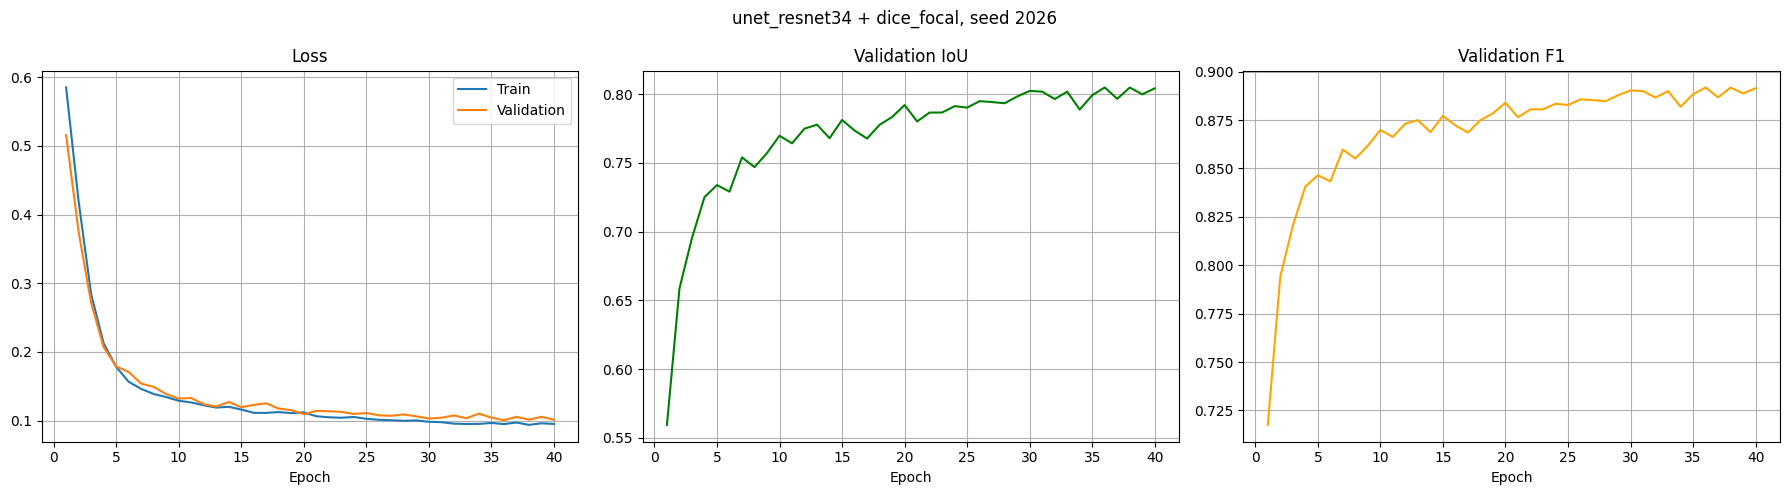

In [97]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)

axes[0].plot(
    final_history_df["epoch"],
    final_history_df["train_loss"],
    label="Train"
)

axes[0].plot(
    final_history_df["epoch"],
    final_history_df["val_loss"],
    label="Validation"
)

axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    final_history_df["epoch"],
    final_history_df["val_iou"],
    color="green"
)

axes[1].set_title("Validation IoU")
axes[1].set_xlabel("Epoch")
axes[1].grid(True)

axes[2].plot(
    final_history_df["epoch"],
    final_history_df["val_f1"],
    color="orange"
)

axes[2].set_title("Validation F1")
axes[2].set_xlabel("Epoch")
axes[2].grid(True)

fig.suptitle(
    f"{BEST_MODEL} + {BEST_LOSS}, "
    f"seed {BEST_SEED_FOR_FIGURES}"
)

plt.tight_layout()

CURVES_DIR = RESULTS_DIR / "curves"
CURVES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

plt.savefig(
    CURVES_DIR / "best_model_training_curves.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()